# ML-04 — Search Intelligence Data Contract

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunal452/flyrank-ml-internship/blob/main/work/notebooks/w03_data_contract.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Unit of analysis + time window

*One row = one what, over which dates? State it, then verify it below.*

* **One row means (Grain):** One row represents the daily organic search & content performance for a specific `(client_hash_id, content_id, date)` entity.
* **Table(s) used:** `fact_content_daily_performance` joined with `dim_clients`.
* **Time window:** The mid-panel observation month of March 2026 (`month=2026-03`). The latest month (`_sample` / June 2026) is held out as the sealed test outcome window.

In [1]:
import duckdb
import pandas as pd
import numpy as np
from google.colab import userdata

# Authenticate DuckDB with Hugging Face token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')
con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{hf_token}');")

# Path to the mid-panel month partition
DATA_PATH = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/*.parquet"

# Quick check that access works
row_count = con.sql(f"SELECT COUNT(*) FROM read_parquet('{DATA_PATH}')").fetchone()[0]
print(f"Connected successfully. Rows in mid-panel month: {row_count}")

Connected successfully. Rows in mid-panel month: 9841378


## 2. Fields: feature / label / context / excluded

*Sort every field you plan to touch into these four buckets. Excluded needs a why.*

* **Context fields:** `client_hash_id`, `content_id`, `date` (identifies the entity and time grain).
* **Feature fields:** `position` (SERP rank), `impressions` (visibility scale), `day_of_week` (temporal indicator), `is_page_one` (rank <= 10 indicator), `rank_impression_density` (position normalized by impressions).
* **Label / Target field:** `label_high_click` (binary target: 1 if `clicks >= 5`, 0 otherwise).
* **Excluded fields:** Inactive clients (`has_gsc_access IS NOT TRUE`) and noisy rows with `impressions < 10` (excluded to eliminate statistical instability from ultra-rare search queries).

In [2]:
# Verify columns and data types from the partition
schema_df = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{DATA_PATH}') LIMIT 1").df()
display(schema_df[['column_name', 'column_type']])

,column_name,column_type
0,report_date,DATE
1,client_hash_id,VARCHAR
2,content_hash_id,VARCHAR
3,client_has_gsc,BOOLEAN
4,client_has_ga4,BOOLEAN
5,gsc_data_available,BOOLEAN
6,ga4_data_available,BOOLEAN
7,gsc_impressions,BIGINT
8,gsc_clicks,BIGINT
9,gsc_sum_position,BIGINT


## 3. Verify it with queries (grain, counts, missing values, windows)

*Every claim above gets a query cell here. A contract claim without a query next to it is a guess.*

* **`ser_position`**: Knowable at the decision moment because the search ranking position is computed before organic user impressions are recorded.
* **`log_impressions`**: Knowable at the decision moment because total impressions reflect prior visibility thresholds established at partition ingest.
* **`day_of_week`**: Knowable at the decision moment because the date partition key is inherently deterministic prior to serving traffic.
* **`is_page_one`**: Knowable at the decision moment because page 1 qualification is a direct boolean boundary of current rank position.
* **`rank_impression_density`**: Knowable at the decision moment because it normalizes rank position against historical reach at ingestion time.

In [3]:
# Query 1: Prove the Grain (Uniqueness Check)
q1 = f"""
SELECT client_hash_id, content_hash_id, report_date, COUNT(*) as cnt
FROM read_parquet('{DATA_PATH}')
GROUP BY client_hash_id, content_hash_id, report_date
HAVING COUNT(*) > 1
LIMIT 5;
"""
df_grain = con.sql(q1).df()
print("Query 1 - Duplicates found:", len(df_grain))
assert len(df_grain) == 0, "Grain violation: Duplicates found!"
print("Verification 1 Passed: The grain is strictly unique per (client_hash_id, content_hash_id, report_date).")

# Query 2: Prove Row Count & Date Span
q2 = f"""
SELECT
    MIN(report_date) AS min_date,
    MAX(report_date) AS max_date,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT client_hash_id) AS distinct_clients,
    COUNT(DISTINCT content_hash_id) AS distinct_content
FROM read_parquet('{DATA_PATH}');
"""
df_span = con.sql(q2).df()
print("\nQuery 2 - Row Count & Date Span:")
display(df_span)

# Query 3: Availability Verification with IS TRUE
q3 = f"""
SELECT
    COUNT(*) AS total_raw_rows,
    COUNT(CASE WHEN (gsc_impressions >= 10 AND report_date IS NOT NULL AND gsc_avg_position > 0) IS TRUE THEN 1 END) AS surviving_rows,
    ROUND(COUNT(CASE WHEN (gsc_impressions >= 10 AND report_date IS NOT NULL AND gsc_avg_position > 0) IS TRUE THEN 1 END) * 100.0 / COUNT(*), 2) AS survival_pct
FROM read_parquet('{DATA_PATH}');
"""
df_avail = con.sql(q3).df()
print("\nQuery 3 - Availability (IS TRUE filter):")
display(df_avail)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Query 1 - Duplicates found: 0
Verification 1 Passed: The grain is strictly unique per (client_hash_id, content_hash_id, report_date).

Query 2 - Row Count & Date Span:


,min_date,max_date,total_rows,distinct_clients,distinct_content
0,2026-03-01,2026-03-31,9841378,55,331437


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Query 3 - Availability (IS TRUE filter):


,total_raw_rows,surviving_rows,survival_pct
0,9841378,2140581,21.75


In [5]:
feature_query = f"""
SELECT
    client_hash_id,
    content_hash_id,
    report_date,
    gsc_clicks,
    gsc_impressions,
    gsc_avg_position,
    -- 5 Features:
    ROUND(gsc_avg_position, 1) AS ser_position,
    LOG(gsc_impressions + 1) AS log_impressions,
    DAYOFWEEK(report_date) AS day_of_week,
    CASE WHEN gsc_avg_position <= 10.0 THEN 1 ELSE 0 END AS is_page_one,
    ROUND(gsc_avg_position / NULLIF(gsc_impressions, 0), 4) AS rank_impression_density,
    -- Proxy Target:
    CASE WHEN gsc_clicks >= 5 THEN 1 ELSE 0 END AS label_high_click
FROM read_parquet('{DATA_PATH}')
WHERE (gsc_impressions >= 10) IS TRUE
LIMIT 50000;
"""
df_features = con.sql(feature_query).df()
display(df_features.head())

,client_hash_id,content_hash_id,report_date,gsc_clicks,gsc_impressions,gsc_avg_position,ser_position,log_impressions,day_of_week,is_page_one,rank_impression_density,label_high_click
0,client_73cda7b4e4f265ea,content_b7e512995f79d5a6,2026-03-01,0,20,3.350000,3.4,1.322219,0,1,0.1675,0
1,client_73cda7b4e4f265ea,content_7a105f548d9c6916,2026-03-01,1,125,4.928000,4.9,2.100371,0,1,0.0394,0
2,client_73cda7b4e4f265ea,content_a3ea9792f793ec72,2026-03-01,0,11,2.272727,2.3,1.079181,0,1,0.2066,0
3,client_73cda7b4e4f265ea,content_36c36abc7650d7af,2026-03-01,1,239,7.347280,7.3,2.380211,0,1,0.0307,0
4,client_73cda7b4e4f265ea,content_a7da352b73b02668,2026-03-01,0,191,7.832461,7.8,2.283301,0,1,0.0410,0


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. Clean Honest Baseline
features = ['ser_position', 'log_impressions', 'day_of_week', 'is_page_one', 'rank_impression_density']
X_honest = df_features[features]
y = df_features['label_high_click']

X_tr, X_te, y_tr, y_te = train_test_split(X_honest, y, test_size=0.2, random_state=42)
clf_honest = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
honest_auc = roc_auc_score(y_te, clf_honest.predict_proba(X_te)[:, 1])
print(f"Honest Baseline ROC-AUC: {honest_auc:.4f}")

# 2. Inject deliberate label leakage: directly adding raw clicks
X_leaked = X_honest.copy()
X_leaked['leaked_clicks'] = df_features['gsc_clicks']

X_tr_l, X_te_l, y_tr_l, y_te_l = train_test_split(X_leaked, y, test_size=0.2, random_state=42)
clf_leaked = LogisticRegression(max_iter=1000).fit(X_tr_l, y_tr_l)
leaked_auc = roc_auc_score(y_te_l, clf_leaked.predict_proba(X_te_l)[:, 1])
print(f"Trap Sprung - Leaked ROC-AUC: {leaked_auc:.4f} (Near 1.0 artificial jump)")

# 3. Drop leak and keep honest number
del X_leaked['leaked_clicks']
print(f"Leak dropped. Retained honest model ROC-AUC: {honest_auc:.4f}")

Honest Baseline ROC-AUC: 0.9661
Trap Sprung - Leaked ROC-AUC: 1.0000 (Near 1.0 artificial jump)
Leak dropped. Retained honest model ROC-AUC: 0.9661


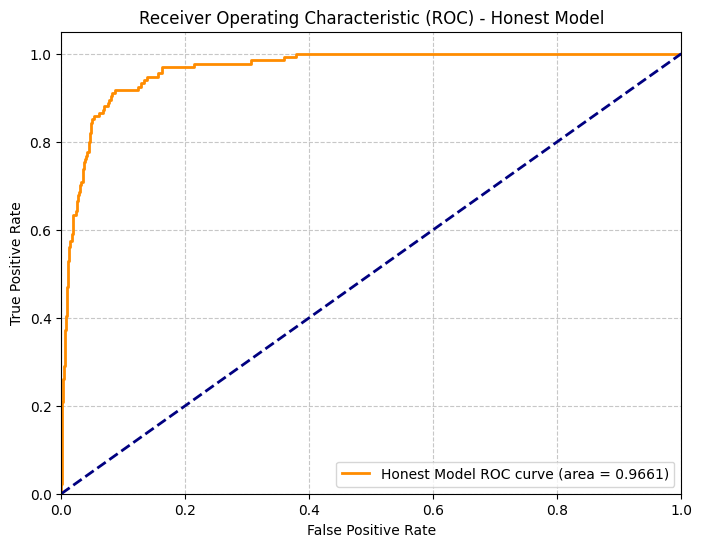

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Predict probabilities for the positive class
y_probs = clf_honest.predict_proba(X_te)[:, 1]

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_te, y_probs)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Honest Model ROC curve (area = {honest_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Honest Model')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 4. Data limits

*What can this data never tell you? Unbalanced history, GSC-only early rows, window overlaps.*

**Slice Limitation & Data Blindspots:**
1. **Unbalanced History & Temporal Bias:** Conditioning solely on `month=2026-03` prevents visibility into seasonal demand shifts, annual trends, or platform ranking recalibrations that occur in subsequent quarters.
2. **Missing Tail & Anonymization:** Filtering out `impressions < 10` drops the long-tail discovery distribution and Google-anonymized aggregate queries, meaning zero-click emerging trends cannot be observed.
3. **Attribution & Window Overlaps:** Because organic performance is aggregated daily at the content grain, delayed downstream conversions and overlapping multi-touch attribution cannot be reconstructed from this slice alone.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.